Heuristic Graph Pathfinding Agent Search Engine

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import heapq

Create Maze

In [2]:
# Create a maze grid
maze = np.array([
    [0, 0, 0, 1, 0, 0, 0],
    [1, 1, 0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 1, 0, 0, 0],
    [1, 1, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 0, 0, 0]
])

start = (0, 0)
goal = (6, 6)

print("Maze:")
print(maze)
print("Start:", start)
print("Goal:", goal)

Maze:
[[0 0 0 1 0 0 0]
 [1 1 0 1 0 1 0]
 [0 0 0 0 0 1 0]
 [0 1 1 1 0 1 0]
 [0 0 0 1 0 0 0]
 [1 1 0 0 0 1 0]
 [0 0 0 1 0 0 0]]
Start: (0, 0)
Goal: (6, 6)


Maze visualize

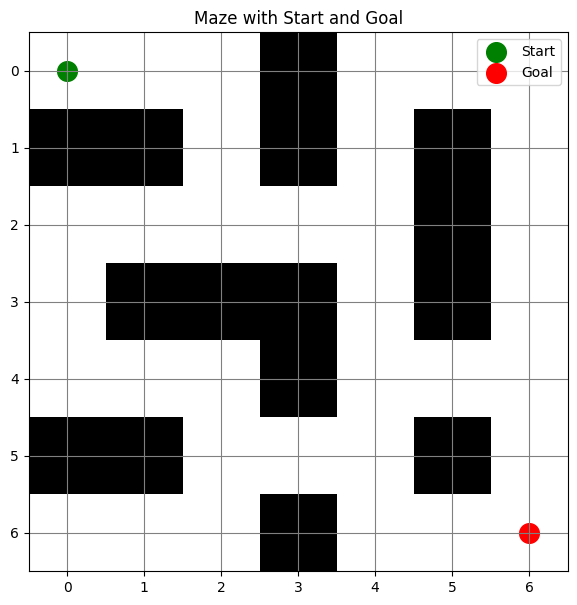

In [3]:
def draw_maze(maze, start, goal, path=None):
    plt.figure(figsize=(7, 7))
    plt.imshow(maze, cmap="binary")

    plt.xticks(range(maze.shape[1]))
    plt.yticks(range(maze.shape[0]))
    plt.grid(True, color="gray")

    plt.scatter(start[1], start[0], color="green", s=200, label="Start")
    plt.scatter(goal[1], goal[0], color="red", s=200, label="Goal")

    if path:
        rows = [p[0] for p in path]
        cols = [p[1] for p in path]
        plt.plot(cols, rows, color="blue", linewidth=3, label="Path")

    plt.legend()
    plt.title("Maze with Start and Goal")
    plt.show()

draw_maze(maze, start, goal)

Heuristic function (Manhattan Distance)

In [4]:
def heuristic(node, goal):
    return abs(node[0] - goal[0]) + abs(node[1] - goal[1])

print("Heuristic distance:", heuristic(start, goal))

Heuristic distance: 12


Valid neighboring cells

In [5]:
def get_neighbors(node, maze):
    rows, cols = maze.shape
    r, c = node

    directions = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    neighbors = []

    for dr, dc in directions:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if maze[nr, nc] == 0:
                neighbors.append((nr, nc))

    return neighbors

print("Start neighbors:", get_neighbors(start, maze))

Start neighbors: [(0, 1)]


A* Search Algorithm

In [6]:
def astar(maze, start, goal):
    open_list = []
    heapq.heappush(open_list, (0, start))

    came_from = {}
    g_score = {start: 0}
    visited = set()
    expanded_nodes = []

    while open_list:
        _, current = heapq.heappop(open_list)

        if current in visited:
            continue

        visited.add(current)
        expanded_nodes.append(current)

        if current == goal:
            path = []
            while current in came_from:
                path.append(current)
                current = came_from[current]

            path.append(start)
            path.reverse()

            return path, expanded_nodes

        for neighbor in get_neighbors(current, maze):
            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(open_list, (f_score, neighbor))

    return None, expanded_nodes

Run A* and display result

Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4), (4, 5), (4, 6), (5, 6), (6, 6)]
Steps: 12
Expanded Nodes: 16
Runtime: 0.0003521442413330078 seconds


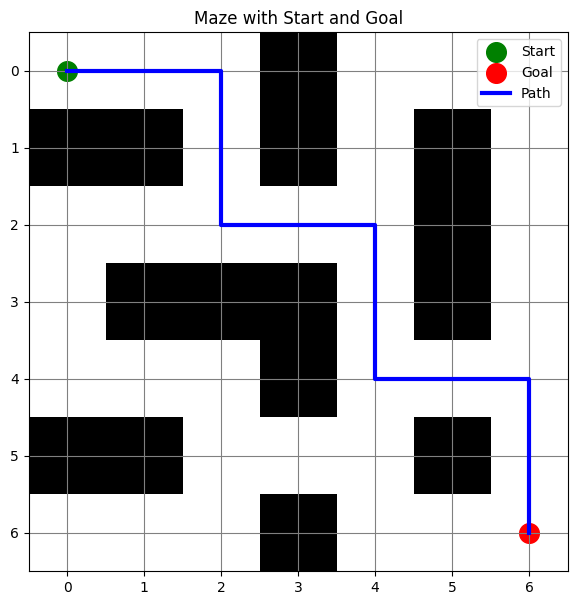

In [7]:
start_time = time.time()

path, expanded_nodes = astar(maze, start, goal)

end_time = time.time()
runtime = end_time - start_time

print("Path:", path)
print("Steps:", len(path) - 1 if path else "No path found")
print("Expanded Nodes:", len(expanded_nodes))
print("Runtime:", runtime, "seconds")

draw_maze(maze, start, goal, path)

Dijkstra Algorithm

In [8]:
def dijkstra(maze, start, goal):
    open_list = []
    heapq.heappush(open_list, (0, start))

    distances = {start: 0}
    came_from = {}
    visited = set()
    expanded_nodes = []

    while open_list:
        current_distance, current = heapq.heappop(open_list)

        if current in visited:
            continue

        visited.add(current)
        expanded_nodes.append(current)

        if current == goal:
            path = []

            while current in came_from:
                path.append(current)
                current = came_from[current]

            path.append(start)
            path.reverse()

            return path, expanded_nodes

        for neighbor in get_neighbors(current, maze):
            new_distance = current_distance + 1

            if new_distance < distances.get(neighbor, float("inf")):
                distances[neighbor] = new_distance
                came_from[neighbor] = current

                heapq.heappush(open_list, (new_distance, neighbor))

    return None, expanded_nodes

Run Dijkstra

Dijkstra Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4), (4, 5), (4, 6), (5, 6), (6, 6)]
Steps: 12
Expanded Nodes: 32
Runtime: 0.0002696514129638672 seconds


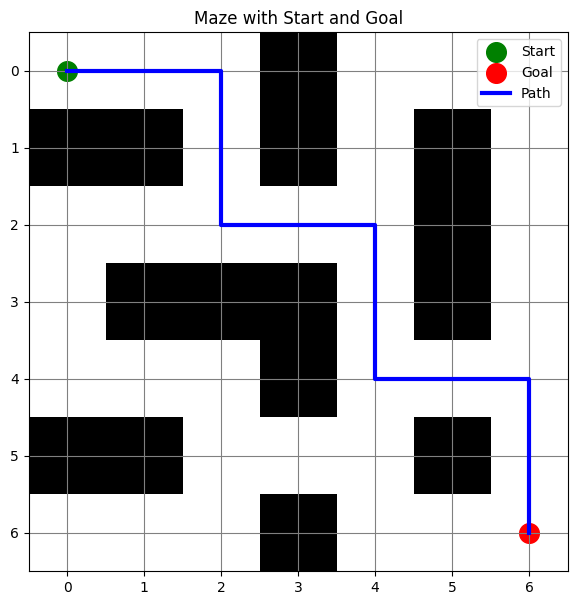

In [9]:
start_time = time.time()

dijkstra_path, dijkstra_expanded = dijkstra(maze, start, goal)

dijkstra_runtime = time.time() - start_time

print("Dijkstra Path:", dijkstra_path)
print("Steps:", len(dijkstra_path) - 1 if dijkstra_path else "No path")
print("Expanded Nodes:", len(dijkstra_expanded))
print("Runtime:", dijkstra_runtime, "seconds")

draw_maze(maze, start, goal, dijkstra_path)

Compare A* and Dijkstra

In [10]:
print("----- Algorithm Comparison -----")

print("A* Steps:", len(path) - 1 if path else "No path")
print("A* Expanded Nodes:", len(expanded_nodes))
print("A* Runtime:", runtime)

print()

print("Dijkstra Steps:", len(dijkstra_path) - 1 if dijkstra_path else "No path")
print("Dijkstra Expanded Nodes:", len(dijkstra_expanded))
print("Dijkstra Runtime:", dijkstra_runtime)

----- Algorithm Comparison -----
A* Steps: 12
A* Expanded Nodes: 16
A* Runtime: 0.0003521442413330078

Dijkstra Steps: 12
Dijkstra Expanded Nodes: 32
Dijkstra Runtime: 0.0002696514129638672


Comparison chart

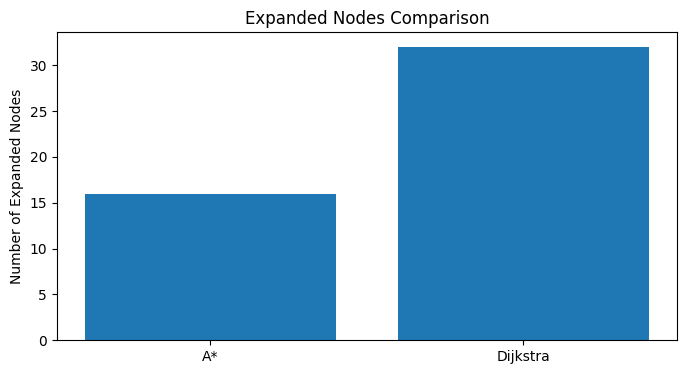

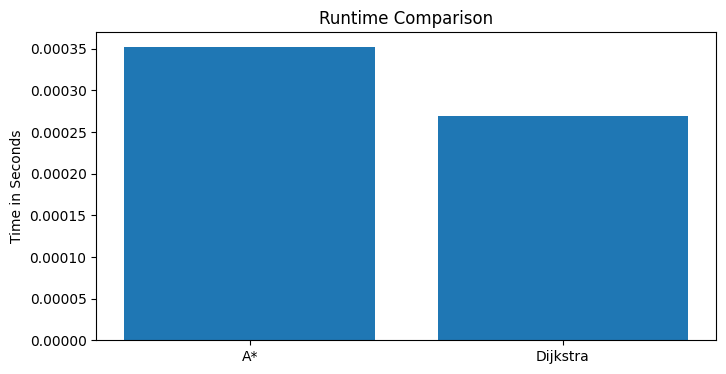

In [11]:
algorithms = ["A*", "Dijkstra"]
steps = [
    len(path) - 1 if path else 0,
    len(dijkstra_path) - 1 if dijkstra_path else 0
]
expanded = [len(expanded_nodes), len(dijkstra_expanded)]
runtimes = [runtime, dijkstra_runtime]

plt.figure(figsize=(8, 4))
plt.bar(algorithms, expanded)
plt.title("Expanded Nodes Comparison")
plt.ylabel("Number of Expanded Nodes")
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(algorithms, runtimes)
plt.title("Runtime Comparison")
plt.ylabel("Time in Seconds")
plt.show()

Create additional maze grids

In [12]:
maze_2 = np.array([
    [0, 0, 0, 0, 1, 0, 0],
    [1, 1, 0, 1, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 1],
    [0, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 1, 0],
    [1, 1, 0, 0, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 0]
])

maze_3 = np.array([
    [0, 0, 1, 0, 0, 0, 0],
    [0, 0, 1, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 1, 0],
    [1, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0]
])

print("Maze 2:")
print(maze_2)

print("\nMaze 3:")
print(maze_3)

Maze 2:
[[0 0 0 0 1 0 0]
 [1 1 0 1 1 0 0]
 [0 0 0 0 0 0 1]
 [0 1 1 1 0 0 0]
 [0 0 0 1 0 1 0]
 [1 1 0 0 0 1 0]
 [0 0 0 0 0 0 0]]

Maze 3:
[[0 0 1 0 0 0 0]
 [0 0 1 0 1 1 0]
 [0 0 0 0 0 1 0]
 [1 1 1 1 0 1 0]
 [0 0 0 0 0 0 0]
 [0 1 1 1 1 1 0]
 [0 0 0 0 0 0 0]]


Test algorithms on all mazes

In [13]:
import pandas as pd

test_mazes = {
    "Maze 1": maze,
    "Maze 2": maze_2,
    "Maze 3": maze_3
}

results = []

for maze_name, current_maze in test_mazes.items():
    current_start = (0, 0)
    current_goal = (
        current_maze.shape[0] - 1,
        current_maze.shape[1] - 1
    )

    # A* testing
    t1 = time.time()
    astar_path, astar_expanded = astar(
        current_maze, current_start, current_goal
    )
    astar_time = time.time() - t1

    # Dijkstra testing
    t2 = time.time()
    dijkstra_path_test, dijkstra_expanded_test = dijkstra(
        current_maze, current_start, current_goal
    )
    dijkstra_time = time.time() - t2

    results.append({
        "Maze": maze_name,
        "A* Steps": len(astar_path) - 1 if astar_path else None,
        "A* Expanded Nodes": len(astar_expanded),
        "A* Runtime": astar_time,
        "Dijkstra Steps": len(dijkstra_path_test) - 1
            if dijkstra_path_test else None,
        "Dijkstra Expanded Nodes": len(dijkstra_expanded_test),
        "Dijkstra Runtime": dijkstra_time
    })

results_df = pd.DataFrame(results)
results_df

,Maze,A* Steps,A* Expanded Nodes,A* Runtime,Dijkstra Steps,Dijkstra Expanded Nodes,Dijkstra Runtime
0,Maze 1,12,16,0.000163,12,32,0.000232
1,Maze 2,12,19,0.000178,12,33,0.000239
2,Maze 3,12,15,0.000129,12,27,0.000165


Compare expanded node density

In [14]:
for result in results:
    maze_name = result["Maze"]
    current_maze = test_mazes[maze_name]

    total_cells = current_maze.size

    astar_density = (
        result["A* Expanded Nodes"] / total_cells
    ) * 100

    dijkstra_density = (
        result["Dijkstra Expanded Nodes"] / total_cells
    ) * 100

    result["A* Node Density (%)"] = round(astar_density, 2)
    result["Dijkstra Node Density (%)"] = round(dijkstra_density, 2)

results_df = pd.DataFrame(results)
results_df

,Maze,A* Steps,A* Expanded Nodes,A* Runtime,Dijkstra Steps,Dijkstra Expanded Nodes,Dijkstra Runtime,A* Node Density (%),Dijkstra Node Density (%)
0,Maze 1,12,16,0.000163,12,32,0.000232,32.65,65.31
1,Maze 2,12,19,0.000178,12,33,0.000239,38.78,67.35
2,Maze 3,12,15,0.000129,12,27,0.000165,30.61,55.10


Visualize one tested maze

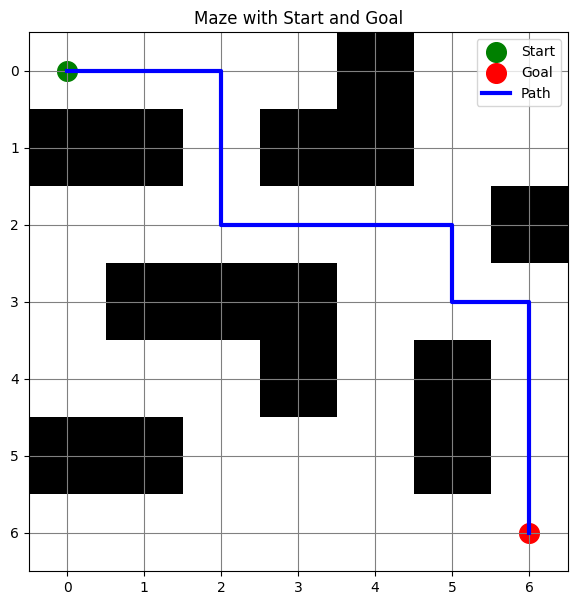

In [15]:
test_start = (0, 0)
test_goal = (6, 6)

test_path, test_expanded = astar(
    maze_2, test_start, test_goal
)

draw_maze(maze_2, test_start, test_goal, test_path)

Export results to CSV

In [16]:
results_df.to_csv("pathfinding_results.csv", index=False)

print("Results saved successfully!")
print("File name: pathfinding_results.csv")

Results saved successfully!
File name: pathfinding_results.csv


In [17]:
from google.colab import files

files.download("pathfinding_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Visualize explored nodes

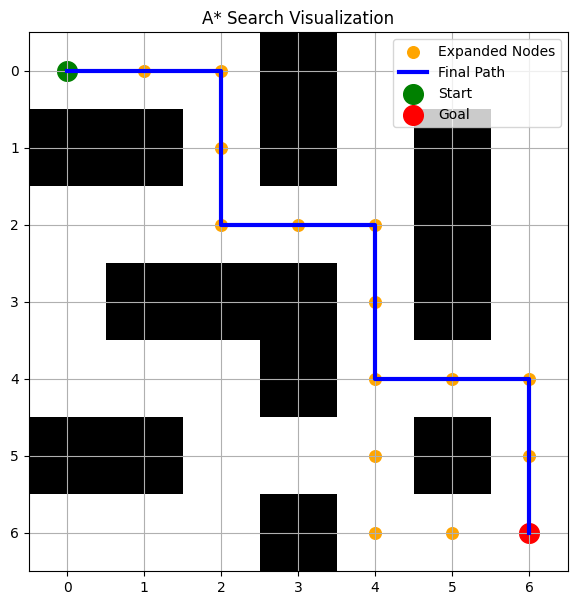

In [23]:
def draw_search_visualization(maze, start, goal, expanded, path=None):
    plt.figure(figsize=(7, 7))
    plt.imshow(maze, cmap="binary")

    # Show explored nodes
    if expanded:
        rows = [node[0] for node in expanded]
        cols = [node[1] for node in expanded]
        plt.scatter(cols, rows, color="orange", s=70, label="Expanded Nodes")

    # Show final path
    if path:
        rows = [node[0] for node in path]
        cols = [node[1] for node in path]
        plt.plot(cols, rows, color="blue", linewidth=3, label="Final Path")

    plt.scatter(start[1], start[0], color="green", s=200, label="Start")
    plt.scatter(goal[1], goal[0], color="red", s=200, label="Goal")

    plt.title("A* Search Visualization")
    plt.legend()
    plt.grid(True)
    plt.savefig("astar_visualization.png", dpi=300, bbox_inches="tight")
    plt.show()

draw_search_visualization(maze, start, goal, expanded_nodes, path)

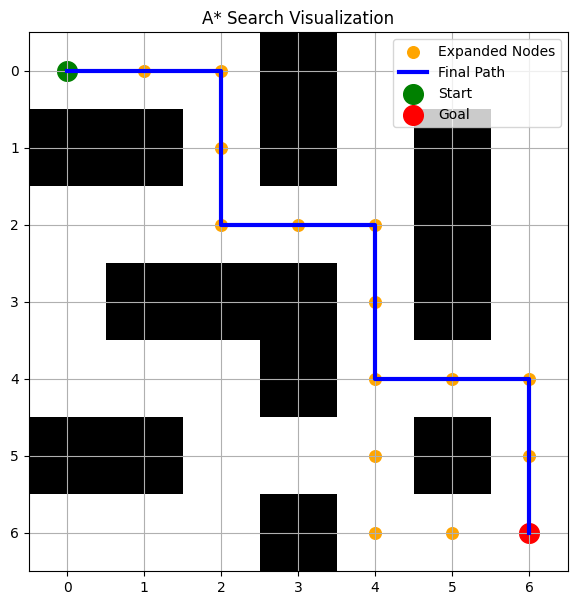

In [24]:
draw_search_visualization(maze, start, goal, expanded_nodes, path)

Save visualization image

<Figure size 700x700 with 0 Axes>

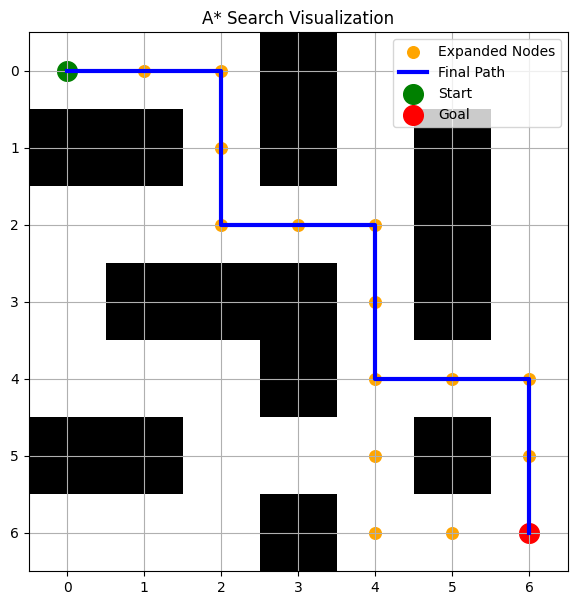

<Figure size 640x480 with 0 Axes>

In [22]:
plt.figure(figsize=(7, 7))

draw_search_visualization(
    maze, start, goal, expanded_nodes, path
)

plt.savefig(
    "astar_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

Save search log

In [20]:
search_log = pd.DataFrame({
    "Node_Row": [node[0] for node in expanded_nodes],
    "Node_Column": [node[1] for node in expanded_nodes]
})

search_log.to_csv("astar_search_log.csv", index=False)

print("Search log saved!")
search_log.head()

Search log saved!


,Node_Row,Node_Column
0,0,0
1,0,1
2,0,2
3,1,2
4,2,2


Download all important files

In [25]:
from google.colab import files

files.download("pathfinding_results.csv")
files.download("astar_search_log.csv")
files.download("astar_visualization.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>